# 02 — Conference Popularity Analysis

Analisis konferensi dengan aktivitas publikasi tertinggi pada periode 2015–2025.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

import matplotlib.pyplot as plt
import pandas as pd

from src import config
from src.viz import SERIES, SURFACE, TEXT_MUTED, apply_style, save

apply_style()

## 1. Data

Analisis memakai dataset bersih. Peringkat hanya mencakup venue konferensi; venue workshop
pendamping (`*_workshops`) dikeluarkan. Trek pendamping seperti Findings, Extended Abstracts,
dan Demos dihitung sebagai bagian dari konferensi induknya.

In [2]:
papers = pd.read_parquet(config.CLEAN_PAPERS, columns=["paper_key", "year", "venue_id", "venue_name", "track"])
conferences = papers[~papers["venue_id"].str.endswith("_workshops")]

pd.Series({
    "Makalah": len(papers),
    "Makalah pada venue konferensi": len(conferences),
    "Venue konferensi": conferences["venue_id"].nunique(),
}).to_frame("jumlah")

,jumlah
Makalah,1996703
Makalah pada venue konferensi,1900336
Venue konferensi,4372


## 2. Top 10 Konferensi berdasarkan Jumlah Publikasi

In [3]:
by_papers = (conferences.pivot_table(index=["venue_id", "venue_name"], columns="track", aggfunc="size", fill_value=0)
             .reindex(columns=["main", "companion"], fill_value=0)
             .rename(columns={"main": "n_main", "companion": "n_companion"})
             .reset_index())
by_papers.columns.name = None
by_papers["n_papers"] = by_papers["n_main"] + by_papers["n_companion"]
by_papers["pct_papers"] = (100 * by_papers["n_papers"] / len(papers)).round(2)
by_papers = by_papers.sort_values(["n_papers", "venue_id"], ascending=[False, True]).reset_index(drop=True)
by_papers.insert(0, "rank", by_papers.index + 1)

top10_papers = by_papers.head(10)
top10_papers.to_csv(config.TABLES_DIR / "top10_conferences_by_papers.csv", index=False)
top10_papers

,rank,venue_id,venue_name,n_main,n_companion,n_papers,pct_papers
0,1,nips,NeurIPS,25178,97,25275,1.27
1,2,icassp,ICASSP,21125,0,21125,1.06
2,3,hci,HCI,19912,0,19912,1.00
3,4,igarss,IGARSS,19685,0,19685,0.99
4,5,aaai,AAAI,18443,0,18443,0.92
5,6,cvpr,CVPR,17429,0,17429,0.87
6,7,embc,EMBC,14677,0,14677,0.74
7,8,chi,CHI,8321,6327,14648,0.73
8,9,emnlp,EMNLP,8766,5686,14452,0.72
9,10,icml,ICML,13628,73,13701,0.69


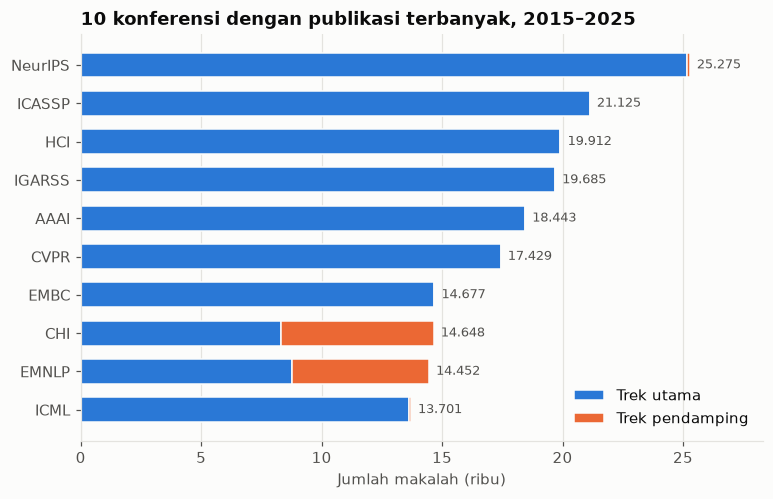

In [4]:
top = top10_papers.iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 4.8))
ax.barh(top["venue_name"], top["n_main"] / 1e3, color=SERIES[0], height=0.65,
        edgecolor=SURFACE, linewidth=1, label="Trek utama")
ax.barh(top["venue_name"], top["n_companion"] / 1e3, left=top["n_main"] / 1e3, color=SERIES[1],
        height=0.65, edgecolor=SURFACE, linewidth=1, label="Trek pendamping")
for y, v in enumerate(top["n_papers"]):
    ax.text(v / 1e3 + 0.3, y, f"{v:,}".replace(",", "."), va="center", fontsize=8.5, color=TEXT_MUTED)
ax.set_xlim(0, top["n_papers"].max() / 1e3 * 1.12)
ax.set_xlabel("Jumlah makalah (ribu)")
ax.set_title("10 konferensi dengan publikasi terbanyak, 2015–2025")
ax.grid(axis="y", visible=False)
ax.legend(loc="lower right")
save(fig, "02_top10_by_papers")
plt.show()

Pengaruh penggabungan trek pendamping terhadap peringkat diperiksa dengan menyusun ulang
peringkat hanya dari trek utama.

In [5]:
main_only = (by_papers.sort_values(["n_main", "venue_id"], ascending=[False, True])
             .head(10)[["venue_id", "venue_name", "n_main"]].reset_index(drop=True))
main_only.insert(0, "rank_main", main_only.index + 1)
main_only["rank_all_tracks"] = main_only["venue_id"].map(by_papers.set_index("venue_id")["rank"])
main_only

,rank_main,venue_id,venue_name,n_main,rank_all_tracks
0,1,nips,NeurIPS,25178,1
1,2,icassp,ICASSP,21125,2
2,3,hci,HCI,19912,3
3,4,igarss,IGARSS,19685,4
4,5,aaai,AAAI,18443,5
5,6,cvpr,CVPR,17429,6
6,7,embc,EMBC,14677,7
7,8,icml,ICML,13628,10
8,9,iros,IROS,12832,12
9,10,icra,ICRA,12361,13


In [6]:
years = conferences[conferences["venue_id"].isin(top10_papers["venue_id"])]
years.pivot_table(index="venue_name", columns="year", aggfunc="size", fill_value=0).loc[top10_papers["venue_name"]]

year,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
venue_name,,,,,,,,,,,
NeurIPS,403,566,677,1009,1449,1918,2562,2834,3540,4494,5823
ICASSP,1198,1322,1321,1395,1735,1863,1723,1864,2720,2678,3306
HCI,1713,1470,1404,1365,1582,2153,1834,2025,2238,1801,2327
IGARSS,1353,1905,1569,2208,2273,1641,2152,1936,2059,2589,0
AAAI,673,691,783,1100,1340,1864,1960,1623,2034,2867,3508
CVPR,601,643,783,979,1294,1462,1660,2068,2353,2715,2871
EMBC,2004,1578,1124,1473,1669,1462,1639,1105,1237,1386,0
CHI,932,1125,1057,1203,1293,1318,1242,1128,1477,1705,2168
EMNLP,312,264,343,577,732,1235,1319,1487,2242,2450,3491
